In [30]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler

# loading and splitting data
df = pd.read_csv("Concrete_Data.csv")
X = df.iloc[:, :8].values
y = df.iloc[:, 8].values

test_idx = list(range(500, 630))
train_idx = []

for i in range(len(df)):
    if i not in test_idx:
        train_idx.append(i)

X_train = X[train_idx]
X_test = X[test_idx]
y_train = y[train_idx]
y_test = y[test_idx]

In [31]:
def compute_mse(y, y_pred):
    return np.mean((y - y_pred) ** 2)

def compute_r2(y, y_pred):
    return 1 - compute_mse(y, y_pred) / np.var(y)

def predict(X, w, b):
    return np.dot(X, w) + b

# gradient descent algo
def gradient_descent(X, y, learning_rate=0.01, num_iterations=1000):
    n, p = X.shape
    w = np.zeros(p)
    b = 0.0
    losses = []

    for i in range(num_iterations):
        y_pred = predict(X, w, b)
        error = y_pred - y
        losses.append(compute_mse(y, y_pred))

        w = w - learning_rate * (2 / n) * np.dot(X.T, error)
        b = b - learning_rate * (2 / n) * np.sum(error)

    return w, b, losses

Untransformed
Train MSE: 104.51672058893884
Test MSE: 138.59765444836583
Train R2: 0.6227031238736043
Test R2: 0.38062136851647954
Standardized
Train MSE: 104.14385119066354
Test MSE: 141.23399343455216
Train R2: 0.6240491521299414
Test R2: 0.36883984133342695


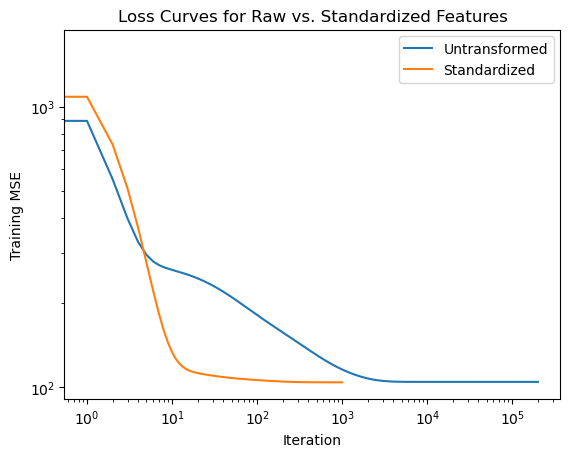

In [40]:
# Scaling & Convergence Speed
# GD on untransformed + standardized features

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

# untransformed
w_raw, b_raw, losses_raw = gradient_descent(X_train, y_train, learning_rate=5e-7, num_iterations=200000)

train_pred_raw = predict(X_train, w_raw, b_raw)
test_pred_raw = predict(X_test, w_raw, b_raw)

print("Untransformed")
print("Train MSE:", compute_mse(y_train, train_pred_raw))
print("Test MSE:", compute_mse(y_test, test_pred_raw))
print("Train R2:", compute_r2(y_train, train_pred_raw))
print("Test R2:", compute_r2(y_test, test_pred_raw))

# standardized
w_s, b_s, losses_s = gradient_descent(X_train_s, y_train, learning_rate=0.1, num_iterations=1000)

train_pred_s = predict(X_train_s, w_s, b_s)
test_pred_s = predict(X_test_s, w_s, b_s)

print("Standardized")
print("Train MSE:", compute_mse(y_train, train_pred_s))
print("Test MSE:", compute_mse(y_test, test_pred_s))
print("Train R2:", compute_r2(y_train, train_pred_s))
print("Test R2:", compute_r2(y_test, test_pred_s))

plt.plot(losses_raw, label="Untransformed")
plt.plot(losses_s, label="Standardized")
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.xscale("log")
plt.yscale("log")
plt.title("Loss Curves for Raw vs. Standardized Features")
plt.legend()
plt.show()

In [41]:
# Scaling & The Optimal Solution
# linear regression on untransformed + standardized features

from sklearn.linear_model import LinearRegression

# untransformed
lr_raw = LinearRegression()
lr_raw.fit(X_train, y_train)

train_pred_lr_raw = lr_raw.predict(X_train)
test_pred_lr_raw = lr_raw.predict(X_test)

print("Untransformed")
print("Train MSE:", compute_mse(y_train, train_pred_lr_raw))
print("Test MSE:", compute_mse(y_test, test_pred_lr_raw))
print("Train R2:", compute_r2(y_train, train_pred_lr_raw))
print("Test R2:", compute_r2(y_test, test_pred_lr_raw))

# standardized
lr_std = LinearRegression()
lr_std.fit(X_train_s, y_train)

train_pred_lr_std = lr_std.predict(X_train_s)
test_pred_lr_std = lr_std.predict(X_test_s)

print("Standardized")
print("Train MSE:", compute_mse(y_train, train_pred_lr_std))
print("Test MSE:", compute_mse(y_test, test_pred_lr_std))
print("Train R2:", compute_r2(y_train, train_pred_lr_std))
print("Test R2:", compute_r2(y_test, test_pred_lr_std))

print(lr_raw.coef_)
print(lr_std.coef_ / scaler.scale_)

Untransformed
Train MSE: 104.14373897310753
Test MSE: 141.31386470839053
Train R2: 0.6240495572262081
Test R2: 0.36848290484354373
Standardized
Train MSE: 104.14373897310753
Test MSE: 141.31386470839016
Train R2: 0.6240495572262081
Test R2: 0.3684829048435454
[ 0.13244887  0.1247277   0.10614715 -0.13410002  0.11723871  0.02854652
  0.03383504  0.11880428]
[ 0.13244887  0.1247277   0.10614715 -0.13410002  0.11723871  0.02854652
  0.03383504  0.11880428]


Train MSE: 55.90222026920746
Test MSE: 55.141026369389
Train R2: 0.7981975232551085
Test R2: 0.7535804369330612


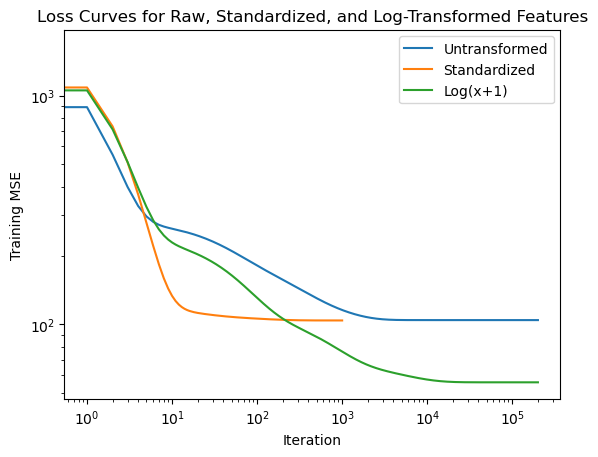

In [42]:
# Non-Linear Transformations
# plot

X_train_log = np.log1p(X_train)
X_test_log = np.log1p(X_test)

w_log, b_log, losses_log = gradient_descent(X_train_log, y_train, learning_rate=5e-3, num_iterations=200000)

train_pred_log = predict(X_train_log, w_log, b_log)
test_pred_log = predict(X_test_log, w_log, b_log)
print("Train MSE:", compute_mse(y_train, train_pred_log))
print("Test MSE:", compute_mse(y_test, test_pred_log))
print("Train R2:", compute_r2(y_train, train_pred_log))
print("Test R2:", compute_r2(y_test, test_pred_log))

plt.plot(losses_raw, label="Untransformed")
plt.plot(losses_s, label="Standardized")
plt.plot(losses_log, label="Log(x+1)")
plt.xlabel("Iteration")
plt.ylabel("Training MSE")
plt.xscale("log")
plt.yscale("log")
plt.title("Loss Curves for Raw, Standardized, and Log-Transformed Features")
plt.legend()
plt.show()

In [48]:
# Non-Linear Transformations
# summary table

lr_log = LinearRegression()
lr_log.fit(X_train_log, y_train)

models = [["Untransformed", lr_raw, X_train, X_test], ["Standardized", lr_std, X_train_s, X_test_s], ["Log-Transformed", lr_log, X_train_log, X_test_log],]

rows = []
for name, model, Xtr, Xte in models:
    train_pred = model.predict(Xtr)
    test_pred = model.predict(Xte)
    rows.append([name, compute_mse(y_train, train_pred), compute_mse(y_test, test_pred), compute_r2(y_train, train_pred), compute_r2(y_test, test_pred)])

summary_table = pd.DataFrame(rows, columns=["Model", "Train MSE", "Test MSE", "Train R2", "Test R2"])

In [35]:
# Univariate vs. Multivariate Coefficients

learning_rates = [1e-6, 7e-5, 1e-4, 2e-5, 1e-2, 1e-6, 8e-7, 1e-4]

for i in range(8):
    x_train_i = X_train[:, [i]]
    x_test_i = X_test[:, [i]]

    w_i, b_i, losses_i = gradient_descent(x_train_i, y_train, learning_rate=learning_rates[i], num_iterations=200000)

    train_pred_i = predict(x_train_i, w_i, b_i)
    test_pred_i = predict(x_test_i, w_i, b_i)

    print("Feature", i)
    print("Learning rate:", learning_rates[i])
    print("m:", w_i[0])
    print("b:", b_i)
    print("Train MSE:", compute_mse(y_train, train_pred_i))
    print("Test MSE:", compute_mse(y_test, test_pred_i))
    print("Train R2:", compute_r2(y_train, train_pred_i))
    print("Test R2:", compute_r2(y_test, test_pred_i))
    print()

Feature 0
Learning rate: 1e-06
m: 0.12402725856926479
b: 0.7171093283385687
Train MSE: 227.80793680889212
Test MSE: 255.61649097356621
Train R2: 0.17763184272841892
Test R2: -0.14232374995068953

Feature 1
Learning rate: 7e-05
m: 0.031598464578992694
b: 34.52189505299822
Train MSE: 269.9646827596595
Test MSE: 310.2141043581357
Train R2: 0.025449412345486144
Test R2: -0.3863148564019121

Feature 2
Learning rate: 0.0001
m: -0.053404320754780264
b: 39.99104174199454
Train MSE: 265.2505810527426
Test MSE: 382.5124134848738
Train R2: 0.04246693679267122
Test R2: -0.7094085475882532

Feature 3
Learning rate: 2e-05
m: 0.15249612816738942
b: 8.382010815029613
Train MSE: 320.8170145905648
Test MSE: 321.8687695050626
Train R2: -0.15812337711279656
Test R2: -0.43839835361428037

Feature 4
Learning rate: 0.01
m: 0.8881414698064518
b: 30.832117453892938
Train MSE: 248.81893443199928
Test MSE: 197.72686280500795
Train R2: 0.10178384708879662
Test R2: 0.11637903123879578

Feature 5
Learning rate: 1e-

In [47]:
names = ["cement", "slag", "fly ash", "water", "superplasticizer",
         "coarse agg", "fine agg", "age"]

output = []
for i in range(8):
    xi = X_train[:, i].reshape(-1, 1)
    model = LinearRegression().fit(xi, y_train)
    output.append([names[i], model.coef_[0], lr_raw.coef_[i]])

table = pd.DataFrame(output, columns=["Feature", "Univariate m", "Multivariate weight"])

In [46]:
# Statistical Significance

import statsmodels.api as sm

ols_raw = sm.OLS(y_train, sm.add_constant(X_train)).fit()
ols_std = sm.OLS(y_train, sm.add_constant(X_train_s)).fit()
ols_log = sm.OLS(y_train, sm.add_constant(X_train_log)).fit()

pvalue_table = pd.DataFrame({"Untransformed p-value": ols_raw.pvalues, "Standardized p-value": ols_std.pvalues, "Log p-value": ols_log.pvalues,})
print(pvalue_table)

   Untransformed p-value  Standardized p-value  Log p-value
0              7.439e-02             0.000e+00    2.866e-01
1              2.492e-40             2.492e-40    1.038e-85
2              6.431e-26             6.431e-26    6.960e-36
3              3.304e-13             3.304e-13    2.919e-01
4              1.790e-03             1.790e-03    1.690e-20
5              2.431e-01             2.431e-01    8.438e-06
6              5.590e-03             5.590e-03    4.049e-01
7              2.973e-03             2.973e-03    8.917e-02
8              8.605e-74             8.605e-74   1.753e-192
